# PyTorch Foundations for Computer Vision

Notebook `01` wrote one training loop, on four numbers per penguin. From here on the data is images, and
every notebook that follows (CNNs, transfer learning, detection) leans on PyTorch
throughout. This notebook is the proper treatment: tensors, datasets, data loaders, modules and the
training loop.

Everything from here on is built from these pieces. It is worth a slow read.

## How to use this notebook

**What you should already know.** Notebook `01` (the five-line training loop, `nn.Sequential`,
cross-entropy, Adam) and NumPy basics.

**Time.** About 2 hours. The training runs take seconds.

**Data.** MNIST, downloaded once to `../data/raw` (about 12 MB). Other notebooks will reuse it.

**How this differs from notebook 01.** There you wrote the loop once, on a table of measurements. Here
the inputs are images, which brings shapes, transforms and `Dataset`s with it, and you take the framework
apart: what a tensor actually is, what the `DataLoader` does for you, what `model.train()` changes, and
what to do when something goes wrong. Nothing here trains on random noise: a model that cannot learn
teaches nothing.

## Learning objectives

After this notebook, you can:

- create, reshape, index and inspect tensors, and move them between NumPy and PyTorch;
- say what shape an image batch has and why, and convert for display;
- write your own `Dataset`, and explain what `DataLoader` adds;
- build a model as an `nn.Module` with `__init__` and `forward`;
- write a training and validation loop from memory;
- explain what `model.train()`, `model.eval()` and `torch.no_grad()` each change.

## 1. Tensors

A tensor is a multi-dimensional array, NumPy's `ndarray` with two additions: it can live on a GPU, and it
can record the operations performed on it so that gradients can be computed backwards through them.

"Multi-dimensional" is the part that makes the word more general than *vector* or *matrix*. The kinds
differ only in how many dimensions they have:

| Dimensions | Name | Example in this course |
|---|---|---|
| 0 | scalar | one loss value |
| 1 | vector | the labels of a batch, `(32,)` |
| 2 | matrix | a batch of penguin measurements, `(239, 4)`, or a weight matrix |
| 3 | | one image: `(channels, height, width)` |
| 4 | | a batch of images: `(batch, channels, height, width)` |
| 5 | | a batch of video clips, with time as the extra dimension (notebook `14`) |

Everything above two dimensions is simply called a tensor. The cell below makes one of each of the first
four and prints the two things you will check most often.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, Subset, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)

scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
batch = torch.zeros(8, 3, 32, 32)

for name, tensor in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("image batch", batch)]:
    print(f"{name:<12} shape {str(tuple(tensor.shape)):<16} dims {tensor.dim()}  dtype {tensor.dtype}")

scalar       shape ()               dims 0  dtype torch.float32
vector       shape (3,)             dims 1  dtype torch.float32
matrix       shape (2, 2)           dims 2  dtype torch.float32
image batch  shape (8, 3, 32, 32)   dims 4  dtype torch.float32


`shape` is the size along each dimension and `dim()` is how many dimensions there are. Those two are the
things you will print most often when debugging, because nearly every PyTorch error is a shape error.

In [2]:
x = torch.arange(24).reshape(2, 3, 4)
print("original     ", tuple(x.shape))
print("x[0]         ", tuple(x[0].shape), "   - the first item")
print("x[:, 0]      ", tuple(x[:, 0].shape), "   - the first row of every item")
print("x.reshape(6,4)", tuple(x.reshape(6, 4).shape))
print("x.flatten()  ", tuple(x.flatten().shape))
print("x.unsqueeze(0)", tuple(x.unsqueeze(0).shape), "- adds a dimension of size 1")
print("x.squeeze()   ", tuple(torch.rand(1, 5, 1).squeeze().shape), "     - removes dimensions of size 1")
print("x.permute(2,0,1)", tuple(x.permute(2, 0, 1).shape), "- reorders the dimensions")

original      (2, 3, 4)
x[0]          (3, 4)    - the first item
x[:, 0]       (2, 4)    - the first row of every item
x.reshape(6,4) (6, 4)
x.flatten()   (24,)
x.unsqueeze(0) (1, 2, 3, 4) - adds a dimension of size 1
x.squeeze()    (5,)      - removes dimensions of size 1
x.permute(2,0,1) (4, 2, 3) - reorders the dimensions


`unsqueeze` and `squeeze` come up constantly with images: a single image is `(1, 28, 28)` and a model
wants a batch, so you `unsqueeze(0)` to get `(1, 1, 28, 28)`. Matplotlib wants `(28, 28)`, so you
`squeeze()`. `permute` reorders dimensions, which is what turns channel-first into channel-last.

### Tensors and NumPy

In [3]:
array = np.array([[1.0, 2.0], [3.0, 4.0]])
tensor = torch.from_numpy(array)          # shares memory with the array
copy = torch.tensor(array)                # makes a copy

array[0, 0] = 99.0
print("from_numpy sees the change:", tensor[0, 0].item())
print("torch.tensor does not     :", copy[0, 0].item())

print("\nback to NumPy:", tensor.numpy().shape)
print("a tensor that needs grad must be detached first: tensor.detach().numpy()")

from_numpy sees the change: 99.0
torch.tensor does not     : 1.0

back to NumPy: (2, 2)
a tensor that needs grad must be detached first: tensor.detach().numpy()


**Key terms.** *Tensor*: a multi-dimensional array that can carry gradients. *dtype*: the numeric type.
*`unsqueeze` / `squeeze`*: add or remove a dimension of size 1. *`permute`*: reorder dimensions.
*`detach`*: drop the gradient history.

## 2. The image convention

PyTorch stores images as `(channels, height, width)`, and a batch as
`(batch, channels, height, width)`. Matplotlib expects `(height, width, channels)`. Almost every confusing
image bug in this course comes from that mismatch.

In [4]:
mnist_train_full = datasets.MNIST(root="../data/raw", train=True, download=True,
                                  transform=transforms.ToTensor())
mnist_test_full = datasets.MNIST(root="../data/raw", train=False, download=True,
                                 transform=transforms.ToTensor())

image, label = mnist_train_full[0]
print("one MNIST image :", tuple(image.shape), "-> 1 channel, 28 high, 28 wide, label", label)
print("value range     :", float(image.min()), "to", float(image.max()))

colour = torch.rand(3, 64, 64)
print("\na colour image  :", tuple(colour.shape))
print("for matplotlib  :", tuple(colour.permute(1, 2, 0).shape))

one MNIST image : (1, 28, 28) -> 1 channel, 28 high, 28 wide, label 5
value range     : 0.0 to 1.0

a colour image  : (3, 64, 64)
for matplotlib  : (64, 64, 3)


`transforms.ToTensor()` did two things at once: it converted the image to a tensor **and** rescaled the
pixels from 0-255 integers to 0.0-1.0 floats. That second part is easy to forget and matters when you
compare with raw pixel data.

Look at what the numbers actually are.

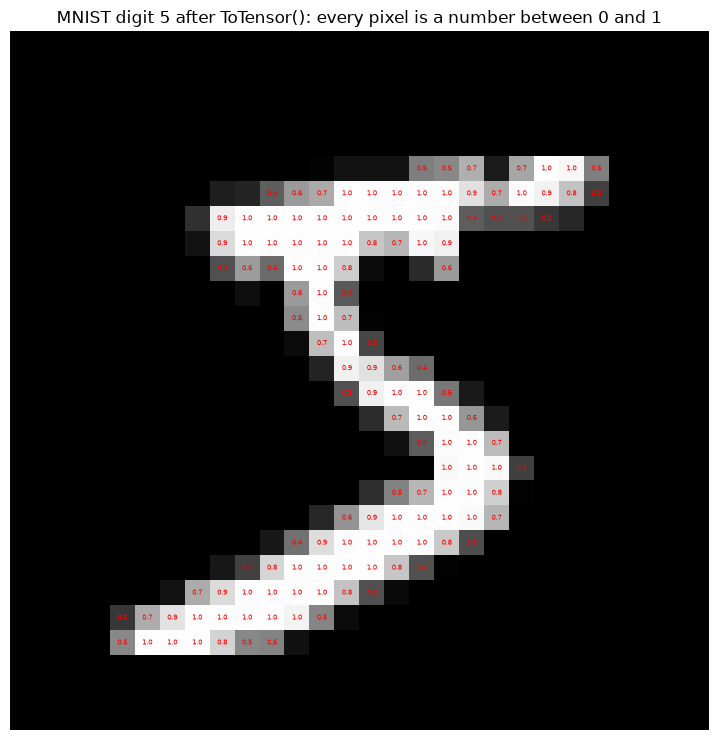

In [5]:
pixels = image.squeeze().numpy()               # (1, 28, 28) -> (28, 28)

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(pixels, cmap="gray")
for row in range(28):
    for column in range(28):
        value = pixels[row, column]
        if value > 0.2:
            ax.text(column, row, f"{value:.1f}", ha="center", va="center", color="red", fontsize=5)
ax.set_title(f"MNIST digit {label} after ToTensor(): every pixel is a number between 0 and 1")
ax.axis("off")
plt.tight_layout()
plt.show()

That is the whole input to the model: 784 numbers between 0 and 1. Everything a network does to an image
happens to numbers like these.

## 3. Dataset and DataLoader

A `Dataset` answers two questions: how many examples are there (`__len__`), and give me example number *i*
(`__getitem__`). That is the entire interface.


In [6]:
# Same results as len(mnist_train_full) but using the __len__ method directly
print("length trainset:", len(mnist_train_full))
print("length trainset:", mnist_train_full.__len__())

# Same results as mnist_train_full[0] but using the __getitem__ method directly
print(mnist_train_full.__getitem__(0))
print(mnist_train_full[0])

length trainset: 60000
length trainset: 60000
(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          

Sometimes you need to write one yourself. Because your data rarely comes in the shape a library expects: the
labels sit in a spreadsheet, two inputs belong together, the files are not in one folder per class, or
you want a *different question* answered from the same images.

**How you write one.** You make a class that inherits from `torch.utils.data.Dataset` (the *superclass*,
which is why it appears between the brackets in `class EvenOddDataset(Dataset)`) and you fill in the two
methods: `__len__` returns the number of examples, `__getitem__(index)` returns one example as an
`(input, label)` pair. The superclass provides everything else, so that the `DataLoader` can batch and
shuffle your class exactly as it does the built-in datasets. An `__init__` is optional; use it to store
what `__getitem__` needs, such as a file list or, below, another dataset.

The dataset below asks MNIST a new question, *is this digit even?*, without copying a single image.

In [7]:
class EvenOddDataset(Dataset):
    """MNIST with a new question: is the digit even? The images are not copied; only the label changes."""

    def __init__(self, base):
        self.base = base                       # any dataset that returns (image, digit)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        image, digit = self.base[index]
        return image, int(digit % 2 == 0)      # 1 for even, 0 for odd


even_odd = EvenOddDataset(Subset(mnist_train_full, range(200)))    # the first 200 digits
print("length:", len(even_odd))
sample_image, sample_label = even_odd[0]
print("one item:", tuple(sample_image.shape), "label", sample_label, f"(the digit is {int(mnist_train_full[0][1])})")

length: 200
one item: (1, 28, 28) label 0 (the digit is 5)


Where are the images? Not in `EvenOddDataset`. It holds only a reference to another dataset
(`self.base`), and when `__getitem__` is asked for item *i* it fetches the image from there and changes
the label. MNIST, in turn, keeps all its images in one big array in memory. That is one choice among many,
and it is exactly what a `Dataset` hides: where the examples live and how they are read is decided inside
the class, and the rest of your code only ever asks for item *i*.

Other datasets make other choices. `ImageFolder` stores only a list of file paths and opens one `.jpg`
from disk each time it is asked. A dataset for a spreadsheet of labels keeps the table and looks up the
row. Which choice is right
depends on the size of the data and the speed of the disk, and you can change it later without touching
the training loop, because the `DataLoader` only ever sees `__len__` and `__getitem__`.

`ImageFolder` is the version you will use for real image projects. Point it at a directory where each
class has its own subfolder and it builds the dataset for you:

```text
data/raw/pets/
    cat/
        cat_0001.jpg
    dog/
        dog_0001.jpg
    ...
```

```python
dataset = datasets.ImageFolder("data/raw/pets", transform=transform)
print(dataset.classes)      # ['cat', 'dog'] - taken from the folder names, sorted
```

### What the DataLoader adds

A `Dataset` gives you one example. A `DataLoader` gives you batches, shuffling, and parallel loading.

In [8]:
loader = DataLoader(mnist_train_full, batch_size=32, shuffle=True)

print("batches per epoch:", len(loader))
batch_images, batch_labels = next(iter(loader))
print("one batch:", tuple(batch_images.shape), tuple(batch_labels.shape))
print("\nthe DataLoader stacked 32 items of shape (1, 28, 28) into one tensor of (32, 1, 28, 28)")

batches per epoch: 1875
one batch: (32, 1, 28, 28) (32,)

the DataLoader stacked 32 items of shape (1, 28, 28) into one tensor of (32, 1, 28, 28)


Three arguments worth knowing:

- **`shuffle=True` for training, `False` for validation and test.** Shuffling training data each epoch
  stops the model from learning the order. Shuffling evaluation data changes nothing about the result and
  makes runs harder to compare.
- **`batch_size`**: the trade-off from notebook `07` (more updates and noisier gradients, or fewer and
  smoother).
- **`num_workers`**: subprocesses that load data in parallel. Worth setting on a machine with several
  cores when loading is the bottleneck; leave at 0 if you hit odd errors on Windows.

### Splitting

Some datasets come already split. MNIST does: `train=True` gives the 60,000 training images and
`train=False` the 10,000 test images, and you never have to decide who goes where. Most datasets do not.
A folder of your own photographs, `ImageFolder` over the Sohas crops in notebook `04`, the video clips in
notebook `15`: those arrive as one pool, and the split is yours to make.

`random_split` does that for a `Dataset`: give it the sizes and it returns two (or three) datasets that
together cover the original once. The `generator` with a fixed seed matters more than it looks. Without
it the split changes every time you run the notebook, and two configurations you compare would be
trained and evaluated on different images; the difference you measure is then partly the split, not the
model. Notebook `10` makes a method of this, and notebook `04` adds the rule that images from the same
source must stay on one side.

In [9]:
train_part, validation_part = random_split(
    even_odd, [150, 50], generator=torch.Generator().manual_seed(42)
)
print(f"{len(train_part)} training, {len(validation_part)} validation")
print("the generator seed makes this split identical on every run - essential for comparing experiments")

150 training, 50 validation
the generator seed makes this split identical on every run - essential for comparing experiments


**Key terms.** *`Dataset`*: knows its length and how to fetch item *i*. *`DataLoader`*: batches,
shuffles, loads in parallel. *`ImageFolder`*: a dataset built from a folder per class. *`random_split`*:
splitting a dataset reproducibly.

## 4. Transforms

A transform is applied to each example as it is loaded. Order matters, and there are two rules.

In [10]:
training_transform = transforms.Compose([
    transforms.RandomRotation(10),                   # augmentation: only for training
    transforms.ToTensor(),                           # PIL image -> tensor, 0-255 -> 0.0-1.0
    transforms.Normalize((0.1307,), (0.3081,)),      # subtract the mean, divide by the spread
])

evaluation_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),      # the same normalization, no augmentation
])

sample = datasets.MNIST(root="../data/raw", train=True, download=False,
                        transform=evaluation_transform)[0][0]
print("after ToTensor + Normalize:", f"min {sample.min():.2f}, max {sample.max():.2f}, mean {sample.mean():.2f}")
print("the values are no longer between 0 and 1 - they are centred on roughly 0")

after ToTensor + Normalize: min -0.42, max 2.82, mean 0.02
the values are no longer between 0 and 1 - they are centred on roughly 0


**Rule one: augmentation goes in the training transform only.** Notebook `09` explains why at length:
your evaluation data must stay a fair sample of reality.

**Rule two: `ToTensor()` comes before `Normalize()`,** because `Normalize` works on tensors. Most
transforms that take a PIL image go before `ToTensor`, and most that take a tensor go after. If you get an
error about a PIL image not having some tensor method, that is the order.

The numbers `0.1307` and `0.3081` are the mean and standard deviation of the MNIST training set. As in
computed from the training data only, applied to everything. Notebook `04` makes a rule of it.

## 5. A model as an `nn.Module`

Two methods. `__init__` creates the layers, `forward` says how data flows through them.

In [11]:
class SmallClassifier(nn.Module):
    def __init__(self, number_of_classes=10):
        super().__init__()                             # never forget this line
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 64),
            nn.ReLU(),
            nn.Linear(64, number_of_classes),
        )

    def forward(self, images):
        return self.network(images)


model = SmallClassifier()
print(model)
print("\nparameters:", sum(p.numel() for p in model.parameters()))

example_batch = torch.rand(4, 1, 28, 28)
print("a batch of 4 in ->", tuple(model(example_batch).shape), "out: 4 rows of 10 class scores")

SmallClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)

parameters: 50890
a batch of 4 in -> (4, 10) out: 4 rows of 10 class scores


Three things worth noting.

`super().__init__()` must be called, or PyTorch cannot register the layers and your model will appear to
have no parameters.

**Never call `model.forward(x)` directly.** Call `model(x)`. The second form runs hooks and mode handling
that the first skips, and the difference shows up in confusing ways much later.

The output is **logits**: raw scores, not probabilities. `nn.CrossEntropyLoss` applies the softmax
itself, so there is no softmax at the end of the network. Adding one is a common and quietly damaging
mistake.

## 6. The training loop

The five lines from notebook `01`, now with a validation pass after every epoch and the model moved to a
`device`. Nothing in the loop itself has changed; what is new is everything around it.

In [12]:
train_data = Subset(mnist_train_full, range(4000))
validation_data = Subset(mnist_test_full, range(1000))

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size=256, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

model = SmallClassifier().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


def train_one_epoch():
    model.train()                                       # training mode: dropout and batchnorm active
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()                           # 1. clear the old gradients
        predictions = model(images)                     # 2. forward pass
        loss = loss_function(predictions, labels)       # 3. how wrong are we
        loss.backward()                                 # 4. backpropagation
        optimizer.step()                                # 5. update the weights
        running_loss += loss.item() * len(labels)
    return running_loss / len(train_data)


def evaluate(loader, dataset):
    model.eval()                                        # evaluation mode
    total_loss = correct = 0
    with torch.no_grad():                               # no gradients needed
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images)
            total_loss += loss_function(predictions, labels).item() * len(labels)
            correct += (predictions.argmax(dim=1) == labels).sum().item()
    return total_loss / len(dataset), correct / len(dataset)


for epoch in range(5):
    train_loss = train_one_epoch()
    validation_loss, validation_accuracy = evaluate(validation_loader, validation_data)
    print(f"epoch {epoch + 1}: train loss {train_loss:.4f} | "
          f"validation loss {validation_loss:.4f} | accuracy {validation_accuracy:.4f}")

device: cpu


epoch 1: train loss 1.3807 | validation loss 0.7976 | accuracy 0.8140


epoch 2: train loss 0.5421 | validation loss 0.5475 | accuracy 0.8530


epoch 3: train loss 0.3852 | validation loss 0.4450 | accuracy 0.8700


epoch 4: train loss 0.3200 | validation loss 0.3907 | accuracy 0.8820


epoch 5: train loss 0.2817 | validation loss 0.3691 | accuracy 0.8850


Those five numbered lines are the loop, and they are the same in every PyTorch project you will ever read.
Learn them in that order.

`optimizer.zero_grad()` is the one people forget. PyTorch *accumulates* gradients by default. Leave it
out and each step uses the sum of all gradients so far, which makes training diverge in a way that looks
mysterious.

### What the two modes actually change

| | `model.train()` | `model.eval()` |
|---|---|---|
| Dropout | active, units randomly switched off | inactive, all units used |
| BatchNorm | uses this batch's statistics, updates its running averages | uses the stored running averages |
| Everything else | identical | identical |

And separately, `torch.no_grad()` stops PyTorch from recording operations for the backward pass. It saves
memory and time, and has no effect on the result. You want both during evaluation, and they are two
different things: `eval()` changes what the layers *do*, `no_grad()` changes what is *recorded*.

### Exercise: change one thing

The training cell above is your baseline: about 0.88 validation accuracy after 5 epochs. Copy it into the
cell below and change **one line at a time**. Run, write down the last line of output, and put the line
back before the next change. Keep `torch.manual_seed(42)` at the top of the cell, so that two runs differ
only in the thing you changed (see *Splitting* above for why).

| Change | Where | Try |
|---|---|---|
| more epochs | `range(5)` | `range(20)` |
| learning rate | `lr=1e-3` | `1e-2`, then `1e-4` |
| hidden layer size | `nn.Linear(28 * 28, 64)` and `nn.Linear(64, ...)` | `256`, then `8` |
| batch size | `batch_size=64` in `train_loader` | `8`, then `1000` |
| forget a line | `optimizer.zero_grad()` | delete it |
| add a softmax | end of `self.network` | `nn.Softmax(dim=1)` |

For each run, answer in one sentence: did the model get better, worse, or did something break? Then, when
the table is full:

1. Which changes are *choices* (a trade-off you could defend either way), and which are *bugs*?
2. Two of the changes make training slower per epoch. Which, and why?
3. With 20 epochs, compare the train loss and the validation loss at the end. What is starting to happen?


In [13]:
torch.manual_seed(42)

# Copy the training cell from section 6 here and change one line.
# Baseline after 5 epochs: validation loss 0.38, accuracy 0.88.


<details>
<summary>Worked answer</summary>

Results on one CPU with seed 42, after 5 epochs unless stated. Your numbers will differ in the last
digits, the direction should not.

| Change | Validation accuracy | What happened |
|---|---|---|
| baseline | 0.88 | train loss 0.27, validation loss 0.38 |
| 20 epochs | 0.90 | train loss keeps falling to 0.07, validation loss stalls at 0.29 from epoch 15 on |
| `lr=1e-2` | 0.90 | faster: 0.88 after the first epoch already |
| `lr=1e-4` | 0.77 | ten times smaller steps, so after 5 epochs it is where the baseline was after 1 |
| hidden 256 | 0.90 | more capacity helps a little; four times the parameters |
| hidden 8 | 0.82 | too narrow: 784 pixels squeezed through 8 numbers |
| `batch_size=8` | 0.89 | eight times more updates per epoch, each noisier; much slower wall-clock time |
| `batch_size=1000` | 0.73 | only 4 updates per epoch, so 20 updates in total; it has barely started |
| no `zero_grad()` | 0.71 | the loss drops and then rises again; gradients from every step are summed |
| `Softmax` at the end | 0.88 | accuracy looks fine but the loss stays at 1.6: softmax applied twice, tiny gradients |

**1. Choices and bugs.** Epochs, learning rate, hidden size and batch size are choices: each has a cost
(time, memory, risk of overfitting) and a reasonable range, and notebooks `07` and `10` are about finding
that range. Removing `zero_grad()` and adding the softmax are bugs. Nothing warns you, the code runs, and
the numbers are just worse than they should be. That is what makes them dangerous.

**2. Slower per epoch.** `batch_size=8` (500 optimizer steps per epoch instead of 63; each step has
overhead) and hidden 256 (four times the multiplications). The learning rate costs nothing per epoch, it
only changes how far each step goes.

**3. Twenty epochs.** Train loss 0.07, validation loss 0.29 and no longer improving. The model is starting
to memorize the 4,000 training images: good on those, no better on new ones. That gap is overfitting, the
subject of notebooks `07` and `08`.

</details>


## Typical mistakes

| Mistake | What you see | What to do |
|---|---|---|
| Forgetting `optimizer.zero_grad()` | the loss rises erratically | it is the first line of the loop |
| Forgetting `model.eval()` | evaluation scores that differ every run | `eval()` before evaluating, `train()` before training |
| Softmax before `CrossEntropyLoss` | the model learns slowly or not at all | end the network with raw logits |
| Calling `model.forward(x)` | subtle problems much later | always call `model(x)` |
| `float64` from NumPy | an error about expected scalar type Double | `.float()` |
| Feeding one image without a batch dimension | a shape error mentioning 4 dimensions | `unsqueeze(0)` |
| Channel order for display | an error about invalid image shape | `permute(1, 2, 0)` |
| `shuffle=True` on validation | results that vary between runs for no reason | shuffle training data only |
| Augmenting the evaluation transform | a score that does not reflect reality | augmentation belongs in the training transform |
| Comparing runs under different seeds | measuring the seed, not the change | seed everything, fix the split |

## Glossary

| Term | In one line |
|---|---|
| Tensor | multi-dimensional array that can carry gradients |
| dtype | numeric type; models want float32, labels int64 |
| `(B, C, H, W)` | batch, channels, height, width - PyTorch's image layout |
| `unsqueeze` / `squeeze` | add or remove a dimension of size 1 |
| `permute` | reorder dimensions, e.g. for matplotlib |
| `Dataset` | knows its length and how to fetch item *i* |
| `DataLoader` | batching, shuffling, parallel loading |
| `ImageFolder` | a dataset built from one folder per class |
| Transform | a function applied to each example as it loads |
| `nn.Module` | a model: `__init__` builds, `forward` runs |
| Logits | raw scores before softmax |
| `model.train()` / `.eval()` | switch dropout and batchnorm behaviour |
| `torch.no_grad()` | stop recording operations for the backward pass |
| Seed | the starting point of a random generator |

## Knowledge check

1. What two things does a tensor have that a NumPy array does not?
2. What shape does a batch of 16 colour images of 64 by 64 have, and what shape does matplotlib want for
   one of them?
3. What are the two methods a `Dataset` must implement?
4. Why should the validation loader not shuffle?
5. Name the five lines of the training loop, in order.
6. What is the difference between `model.eval()` and `torch.no_grad()`?
7. Why is there no softmax at the end of the classifier?
8. Your model gets a `(1, 28, 28)` tensor and complains. What is missing?

<details>
<summary>Suggested answers</summary>

1. It can live on a GPU, and it can record the operations applied to it so that gradients can be
   propagated backwards.
2. `(16, 3, 64, 64)`. For one image matplotlib wants `(64, 64, 3)`, which is `image.permute(1, 2, 0)`.
3. `__len__` and `__getitem__`. That is the whole interface, which is why writing your own is easy.
4. Because it changes nothing about the result and makes runs harder to compare, and if you ever print
   per-example output, it will be in a different order each time.
5. `optimizer.zero_grad()`, forward pass, compute the loss, `loss.backward()`, `optimizer.step()`.
6. `eval()` changes what the layers do: dropout off, batchnorm using stored statistics. `no_grad()`
   changes what PyTorch records, saving memory and time without changing the result. You want both when
   evaluating, and they are unrelated mechanisms.
7. Because `nn.CrossEntropyLoss` applies softmax internally. Doing it twice shrinks the gradients and slows
   training, with no error message to tell you.
8. The batch dimension. Use `unsqueeze(0)` to get `(1, 1, 28, 28)`.

</details>